In [1]:
import numpy as np
from scipy.linalg import svd
from scipy.integrate import odeint
import matplotlib.pyplot as plt
import scipy
from tqdm.notebook import tqdm

In [2]:
def simulate(M, C, K, Ts, N):
    n = M.shape[0]

    # Assemble into state-space matrices
    A = np.block([[np.zeros((n,n)), np.eye(n)],
                [-np.linalg.inv(M) @ K, -np.linalg.inv(M) @ C]])

    B = np.block([np.zeros((n,n)), np.linalg.inv(M)]).T

    # Sampling time
    Ts = 0.01

    # Compute discrete-time matrices
    Ad, Bd, _, _, _ = scipy.signal.cont2discrete((A,B,np.eye(2*n),np.zeros((2*n,n))), Ts)

    # simulation
    x = np.zeros((6,1))
    u = np.random.randn(N)
    y = []
    for n in range(N):
        x_next = np.matmul(Ad, x) + np.matmul(Bd, np.array([u[n],0,0]).reshape(-1,1))
        y.append(x[[0,1]])
        x = x_next.copy()
    return np.array(y).squeeze(), np.linalg.eig(A)

In [3]:
M = np.array([[1, 0, 0],
              [0, 1, 0],
              [0, 0, 1]])

# Damping matrix (C)
C = np.array([[0.1, 0, 0],
              [0, 0.1, 0],
              [0, 0, 0.1]])

# Stiffness matrix (K)
k = 100
K = np.array([[2*k, -1*k, 0],
              [-1*k, 2*k, -1*k],
              [0, -1*k, 1*k]])
Ts = 1 / 256
y, l = simulate(M, C, K, Ts, N=2**12)

In [9]:
class SSI():
    def __init__(self, s: int, m: int):
        self.s = s # max order
        self.m = m # selected order
        self.log = {}
    
    def _get_block_hankel(self, Y: np.ndarray) -> tuple[np.ndarray]:
        M, N = Y.shape
        s2 = 2 * self.s
        Yh = np.vstack([Y[:, k : N - s2 + k] for k in range(0, s2)])
        Yhp = Yh[0:M*self.s]
        Yhf = Yh[M*self.s:]
        return Yhp, Yhf

    def _get_projection_matrix(self, Yhf: np.ndarray, Yhp: np.ndarray) -> np.ndarray:
        Yinv = np.linalg.pinv(np.matmul(Yhp, Yhp.T))
        return np.matmul(
            Yhf, np.matmul(
                Yhp.T, np.matmul(
                    Yinv, Yhp
                )
            )
        )
    
    def _solve(self, A: np.ndarray, B: np.ndarray) -> np.ndarray:
        Ai = np.linalg.pinv(A)
        return np.matmul(Ai, B)

    def _get_A(self, L: np.ndarray) -> np.ndarray:
        m = L.shape[0] // self.s
        L2s = L[m:]
        L1s_1 = L[0:(self.s-1)*m]
        return self.solve(L2s, L1s_1)

    def _compute_svd(self, O: np.ndarray) -> tuple:
        U, S, V = np.linalg.svd(O)
        self.log["s"] = S
        S = np.diag(S)    
        return U, S, V

    def _get_stab(self):
        pass

    def predict(self, Y: np.ndarray) -> np.ndarray:
        Yhp, Yhf = self.get_block_hankel(Y)
        O = self.get_projection_matrix(Yhf, Yhp)
        U, S, V = self.compute_svd(O)
        L = np.matmul(U, np.sqrt(S))
        X0 = np.matmul(np.sqrt(S), U)
        self.Ad = self.get_A(L)
        return self.Ad
    
    def compute_poles(self):
        z, _ = np.linalg.eig(self.Ad)
        # p = np.angle(z)
        # w = np.abs(p)
        # f = fs * w / (2*np.pi)
        # return f
        return z

In [18]:
ssi = SSI(s=12, m=5)
Ad = ssi.predict(y.T)
fest = ssi.compute_poles(fs=1/Ts)

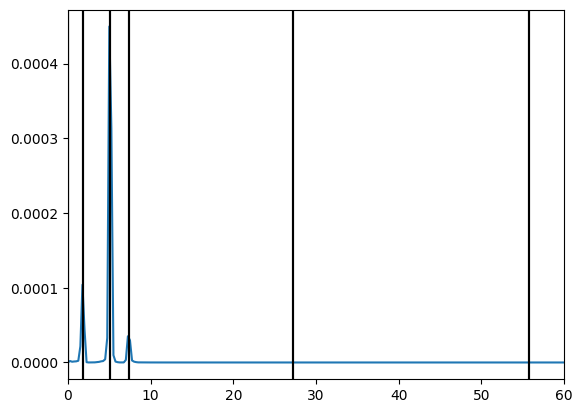

In [20]:
f, X = scipy.signal.welch(y[:,0], fs=1/Ts, nperseg=1024)
plt.plot(f,X)
plt.xlim([0,60])
for fi in fest:
    plt.axvline(fi, color="k")

In [135]:
np.linalg.eig(Ae)

(array([-4.97301732e-09,  4.97301719e-09]),
 array([[ 0.8910246 , -0.8910246 ],
        [ 0.45395503, -0.45395502]]))